# Chest X-Ray Pneumonia Classification with Grad-CAM

MobileNetV2 transfer learning model for Normal vs Pneumonia chest X-ray classification with Grad-CAM visualization.

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os
import getpass
from pathlib import Path


kaggle_json = Path("/root/.kaggle/kaggle.json")

if kaggle_json.exists():
    kaggle_json.unlink()

kaggle_username = input("Kaggle username: ").strip()
kaggle_key = getpass.getpass("Kaggle API key/token: ").strip()

try:
    kaggle_username.encode("ascii")
    kaggle_key.encode("ascii")
except UnicodeEncodeError:
    raise ValueError("Kaggle username or key contains non-ASCII characters. Please copy them directly from Kaggle.")

os.environ["KAGGLE_USERNAME"] = kaggle_username
os.environ["KAGGLE_KEY"] = kaggle_key

print("Kaggle credentials configured for this Colab session.")

In [ ]:
 from pathlib import Path


!rm -rf /content/chest_xray
!rm -rf /content/__MACOSX
!rm -f /content/chest-xray-pneumonia.zip


print("Downloading dataset from Kaggle...")
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content/

print("Unzipping dataset...")
!unzip -q /content/chest-xray-pneumonia.zip -d /content/

candidate_dirs = []

for path in Path("/content").rglob("*"):
    if "__MACOSX" in str(path):
        continue

    if path.is_dir():
        has_train = (path / "train").exists()
        has_test = (path / "test").exists()
        has_normal = (path / "train" / "NORMAL").exists()
        has_pneumonia = (path / "train" / "PNEUMONIA").exists()

        if has_train and has_test and has_normal and has_pneumonia:
            candidate_dirs.append(path)

print("Candidate dataset directories:")
for path in candidate_dirs:
    print(path)

if len(candidate_dirs) == 0:
    raise FileNotFoundError("No valid dataset directory was found. Please check the Kaggle download output.")

base_dir = candidate_dirs[0]

train_dir = base_dir / "train"
val_dir = base_dir / "val"
test_dir = base_dir / "test"

print("\nSelected base directory:", base_dir)
print("Train exists:", train_dir.exists())
print("Validation exists:", val_dir.exists())
print("Test exists:", test_dir.exists())

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [01:51<00:00, 22.1MB/s]

Unzipping dataset...
Candidate dataset directories:
/content/chest_xray
/content/chest_xray/chest_xray

Selected base directory: /content/chest_xray
Train exists: True
Validation exists: True
Test exists: True


In [ ]:
for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = base_dir / split / cls
        image_count = len(list(folder.glob("*")))
        print(f"{cls}: {image_count}")


TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VAL
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds_raw.class_names
print("Class names:", class_names)

Found 5216 files belonging to 2 classes.
Using 4434 files for training.
Found 5216 files belonging to 2 classes.
Using 782 files for validation.
Found 624 files belonging to 2 classes.
Class names: ['NORMAL', 'PNEUMONIA']


In [ ]:
from collections import Counter
import numpy as np

labels = []

for _, label_batch in train_ds_raw:
    labels.extend(label_batch.numpy().astype(int).ravel().tolist())

counts = Counter(labels)
total = sum(counts.values())
num_classes = len(counts)

class_weight = {
    class_id: total / (num_classes * count)
    for class_id, count in counts.items()
}

print("Class names:", class_names)
print("Class counts:", counts)
print("Class weights:", class_weight)

Class names: ['NORMAL', 'PNEUMONIA']
Class counts: Counter({1: 3283, 0: 1151})
Class weights: {1: 0.675296984465428, 0: 1.9261511728931364}


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds_raw.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds_raw.cache().prefetch(AUTOTUNE)
test_ds = test_ds_raw.cache().prefetch(AUTOTUNE)


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.10),
], name="data_augmentation")

base_model = MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=IMG_SIZE + (3,), name="input_image")

x = data_augmentation(inputs)
x = preprocess_input(x)

x = base_model(x, training=False)


x = layers.Activation("linear", name="last_conv_features")(x)

x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.30, name="dropout")(x)

outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)


print("Base model trainable:", base_model.trainable)

model.summary()

Base model trainable: False


Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_2 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv_features (Activation) │ (None, 7, 7, 1280)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 22s 79ms/step - accuracy: 0.8597 - auc: 0.9395 - loss: 0.3316 - precision: 0.9512 - recall: 0.8544 - val_accuracy: 0.9361 - val_auc: 0.9734 - val_loss: 0.1873 - val_precision: 0.9487 - val_recall: 0.9679 - learning_rate: 0.0010
Epoch 2/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step - accuracy: 0.9244 - auc: 0.9808 - loss: 0.1871 - precision: 0.9801 - recall: 0.9165 - val_accuracy: 0.9437 - val_auc: 0.9770 - val_loss: 0.1633 - val_precision: 0.9521 - val_recall: 0.9747 - learning_rate: 0.0010
Epoch 3/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step - accuracy: 0.9366 - auc: 0.9860 - loss: 0.1588 - precision: 0.9829 - recall: 0.9306 - val_accuracy: 0.9450 - val_auc: 0.9808 - val_loss: 0.1445 - val_precision: 0.9629 - val_recall: 0.9645 - learning_rate: 0.0010
Epoch 4/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.9389 - auc: 0.9866 - loss: 0.1474 - precision: 0.9827 - recall: 0.9339 - val_accuracy: 0.9565 - val_auc: 0.9816 - val_loss: 0.1344 - va

In [ ]:

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)


print("Base model trainable:", base_model.trainable)

trainable_count = sum([layer.trainable for layer in base_model.layers])
print("Number of trainable layers in the base model:", trainable_count)

Base model trainable: True
Number of trainable layers in the base model: 30


In [ ]:
history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 22s 90ms/step - accuracy: 0.9260 - auc: 0.9758 - loss: 0.2128 - precision: 0.9593 - recall: 0.9400 - val_accuracy: 0.9616 - val_auc: 0.9865 - val_loss: 0.1158 - val_precision: 0.9731 - val_recall: 0.9764 - learning_rate: 1.0000e-05
Epoch 2/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 78ms/step - accuracy: 0.9423 - auc: 0.9862 - loss: 0.1457 - precision: 0.9822 - recall: 0.9391 - val_accuracy: 0.9655 - val_auc: 0.9878 - val_loss: 0.1050 - val_precision: 0.9846 - val_recall: 0.9696 - learning_rate: 1.0000e-05
Epoch 3/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.9506 - auc: 0.9913 - loss: 0.1165 - precision: 0.9857 - recall: 0.9470 - val_accuracy: 0.9680 - val_auc: 0.9881 - val_loss: 0.1026 - val_precision: 0.9880 - val_recall: 0.9696 - learning_rate: 1.0000e-05
Epoch 4/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.9553 - auc: 0.9933 - loss: 0.1016 - precision: 0.9871 - recall: 0.9522 - val_accuracy: 0.9604 - val_auc: 0.9889 - val_lo

In [ ]:
test_results = model.evaluate(test_ds, return_dict=True)

print("TEST RESULTS")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.8798 - auc: 0.9615 - loss: 0.3525 - precision: 0.8539 - recall: 0.9744
TEST RESULTS
accuracy: 0.8798
auc: 0.9615
loss: 0.3525
precision: 0.8539
recall: 0.9744


Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.94      0.72      0.82       234
   PNEUMONIA       0.85      0.97      0.91       390

    accuracy                           0.88       624
   macro avg       0.90      0.85      0.86       624
weighted avg       0.89      0.88      0.88       624



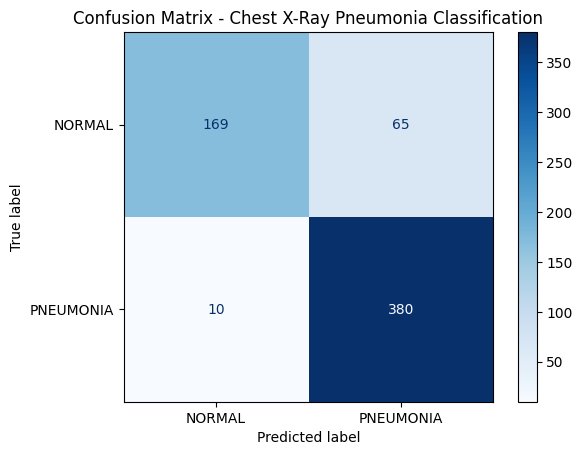

Confusion Matrix:
[[169  65]
 [ 10 380]]


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

y_true = []
y_prob = []

for images, labels in test_ds_raw:
    probs = model.predict(images, verbose=0).ravel()
    y_prob.extend(probs)
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)


y_pred = (y_prob >= 0.5).astype(int)

print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Chest X-Ray Pneumonia Classification")
plt.show()

print("Confusion Matrix:")
print(cm)

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import random

def make_gradcam_heatmap(img_array, model, last_conv_layer_name="last_conv_features"):
    grad_model = tf.keras.models.Model(
        model.inputs,
        [
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)


        pneumonia_prob = predictions[:, 0]


        loss = tf.where(
            pneumonia_prob >= 0.5,
            pneumonia_prob,
            1.0 - pneumonia_prob
        )

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()


def load_image_for_prediction(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    return img_array


def display_gradcam(img_path, model, alpha=0.35):
    img_array = load_image_for_prediction(img_path)

    pneumonia_prob = model.predict(img_array, verbose=0)[0][0]

    if pneumonia_prob >= 0.5:
        pred_class = "PNEUMONIA"
        confidence = pneumonia_prob
    else:
        pred_class = "NORMAL"
        confidence = 1 - pneumonia_prob

    heatmap = make_gradcam_heatmap(img_array, model)

    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE)

    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    superimposed_img = heatmap_color * alpha + img
    superimposed_img = np.uint8(superimposed_img)

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original X-Ray")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(superimposed_img)
    plt.title(f"Grad-CAM | Pred: {pred_class} | Conf: {confidence:.2f}")
    plt.axis("off")

    plt.show()



NORMAL test image count: 234
PNEUMONIA test image count: 390
Image: /content/chest_xray/test/NORMAL/IM-0063-0001.jpeg


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_image']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


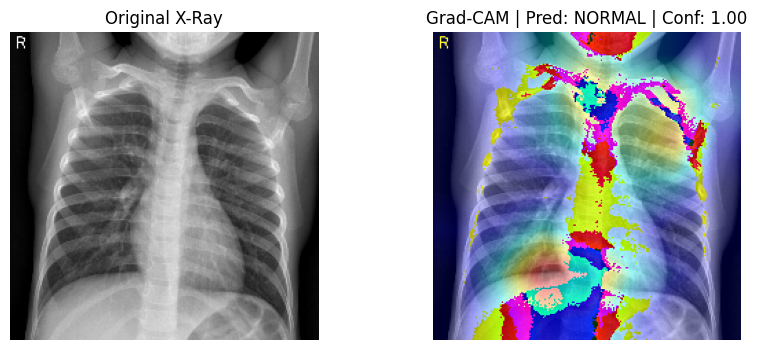

Image: /content/chest_xray/test/PNEUMONIA/person1671_virus_2887.jpeg


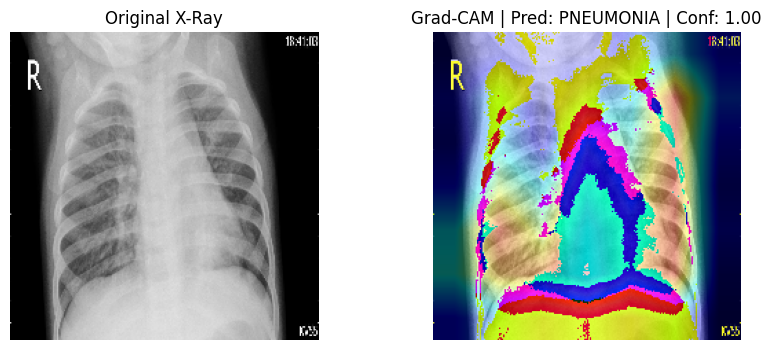

Image: /content/chest_xray/test/NORMAL/NORMAL2-IM-0381-0001.jpeg


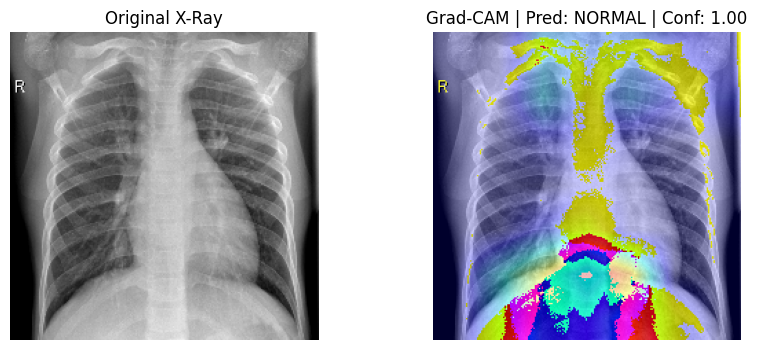

Image: /content/chest_xray/test/PNEUMONIA/person145_bacteria_696.jpeg


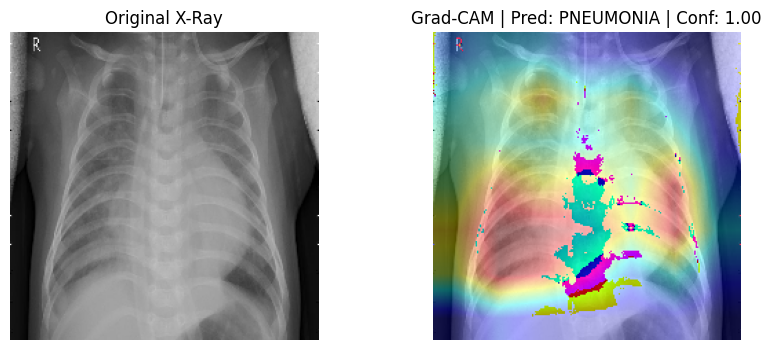

In [ ]:
from pathlib import Path
import random

normal_images = list((test_dir / "NORMAL").glob("*"))
pneumonia_images = list((test_dir / "PNEUMONIA").glob("*"))

print("NORMAL test image count:", len(normal_images))
print("PNEUMONIA test image count:", len(pneumonia_images))

sample_images = [
    random.choice(normal_images),
    random.choice(pneumonia_images),
    random.choice(normal_images),
    random.choice(pneumonia_images),
]

for img_path in sample_images:
    print("Image:", img_path)
    display_gradcam(img_path, model)

In [ ]:
def display_gradcam_clean(img_path, model, alpha=0.30, threshold=0.25):
    img_array = load_image_for_prediction(img_path)

    pneumonia_prob = model.predict(img_array, verbose=0)[0][0]

    if pneumonia_prob >= 0.5:
        pred_class = "PNEUMONIA"
        confidence = pneumonia_prob
    else:
        pred_class = "NORMAL"
        confidence = 1 - pneumonia_prob

    true_class = Path(img_path).parent.name

    heatmap = make_gradcam_heatmap(img_array, model)


    heatmap = np.where(heatmap >= threshold, heatmap, 0)

    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE)

    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    superimposed_img = heatmap_color * alpha + img
    superimposed_img = np.uint8(superimposed_img)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title(f"Original\nTrue: {true_class}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_img)
    plt.title(f"Overlay\nPred: {pred_class} | Conf: {confidence:.2f}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()



Image: /content/chest_xray/test/NORMAL/NORMAL2-IM-0150-0001.jpeg


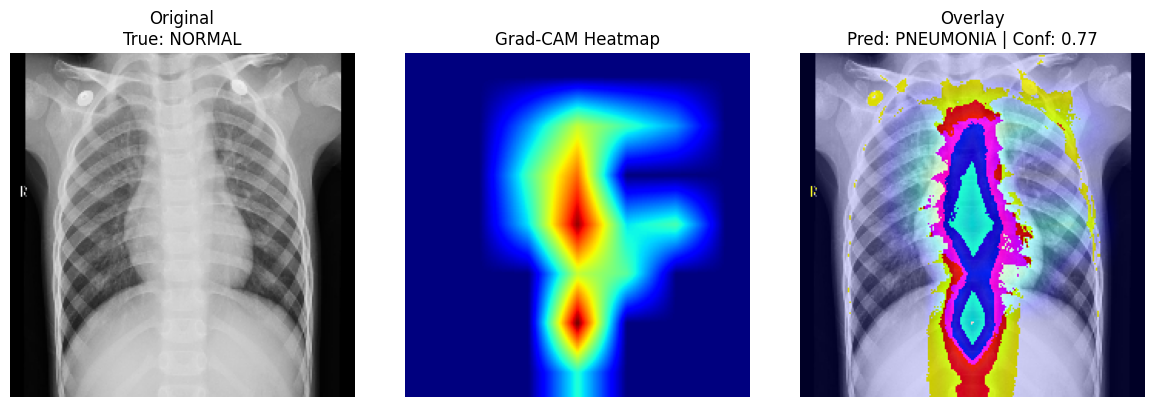

Image: /content/chest_xray/test/PNEUMONIA/person174_bacteria_832.jpeg


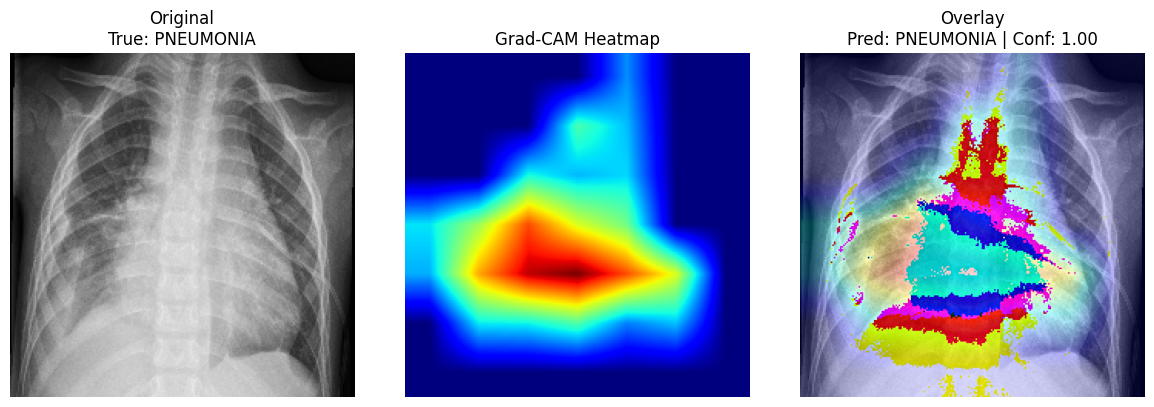

Image: /content/chest_xray/test/NORMAL/NORMAL2-IM-0282-0001.jpeg


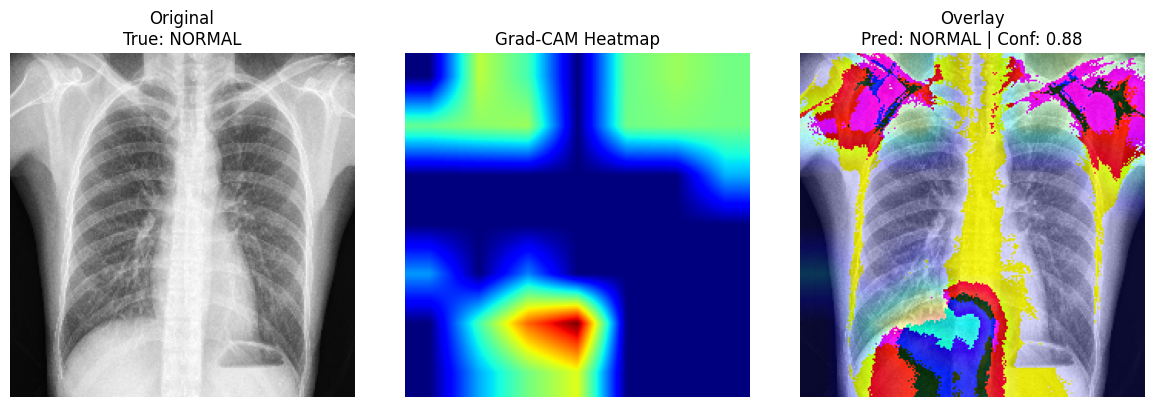

Image: /content/chest_xray/test/PNEUMONIA/person1651_virus_2855.jpeg


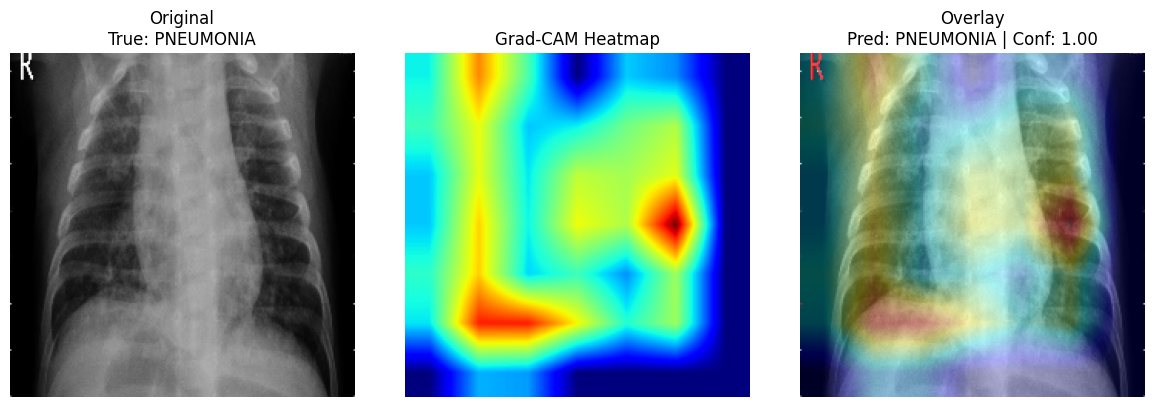

In [ ]:
sample_images = [
    random.choice(normal_images),
    random.choice(pneumonia_images),
    random.choice(normal_images),
    random.choice(pneumonia_images),
]

for img_path in sample_images:
    print("Image:", img_path)
    display_gradcam_clean(img_path, model)

In [ ]:
test_file_paths = np.array(test_ds_raw.file_paths)

tn_indices = np.where((y_true == 0) & (y_pred == 0))[0]
tp_indices = np.where((y_true == 1) & (y_pred == 1))[0]
fp_indices = np.where((y_true == 0) & (y_pred == 1))[0]
fn_indices = np.where((y_true == 1) & (y_pred == 0))[0]

print("True Negative:", len(tn_indices))
print("True Positive:", len(tp_indices))
print("False Positive:", len(fp_indices))
print("False Negative:", len(fn_indices))

True Negative: 169
True Positive: 380
False Positive: 65
False Negative: 10



 True Negative: NORMAL correctly predicted
Image: /content/chest_xray/test/NORMAL/IM-0001-0001.jpeg


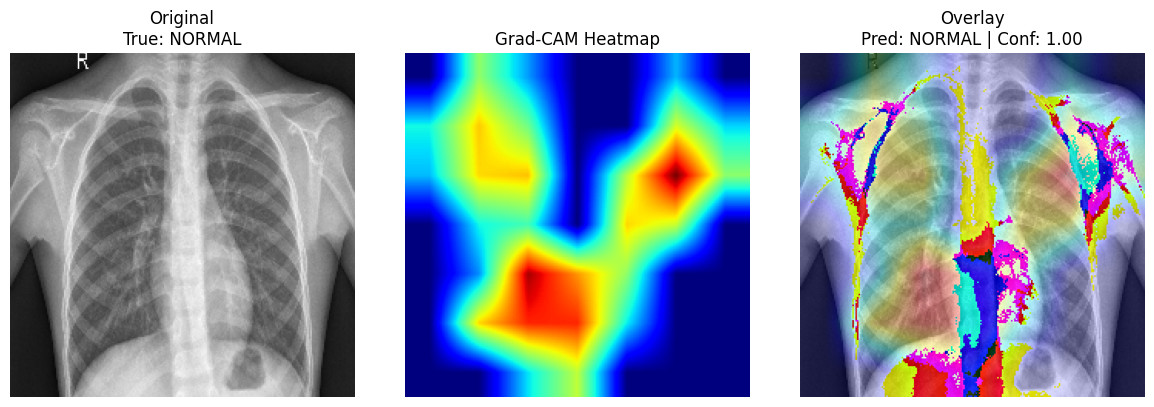


 True Positive: PNEUMONIA correctly predicted
Image: /content/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg


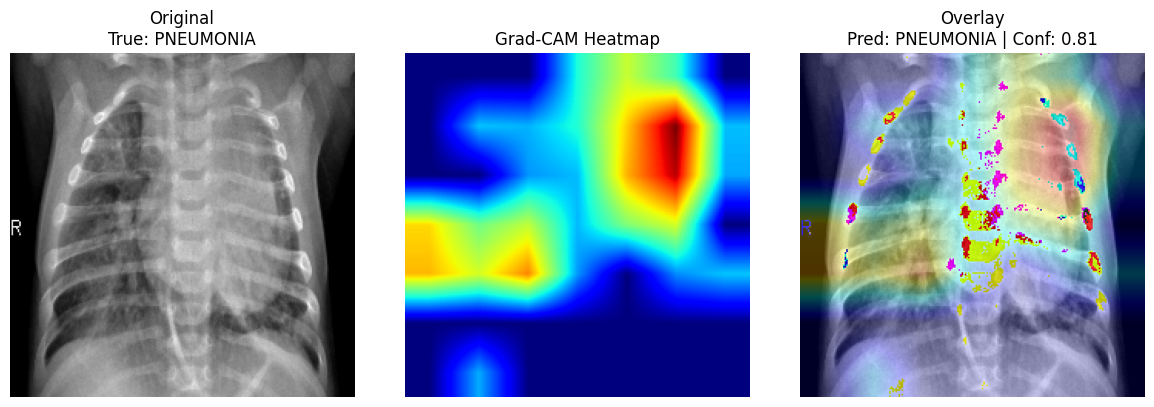


 False Positive: NORMAL predicted as PNEUMONIA
Image: /content/chest_xray/test/NORMAL/IM-0022-0001.jpeg


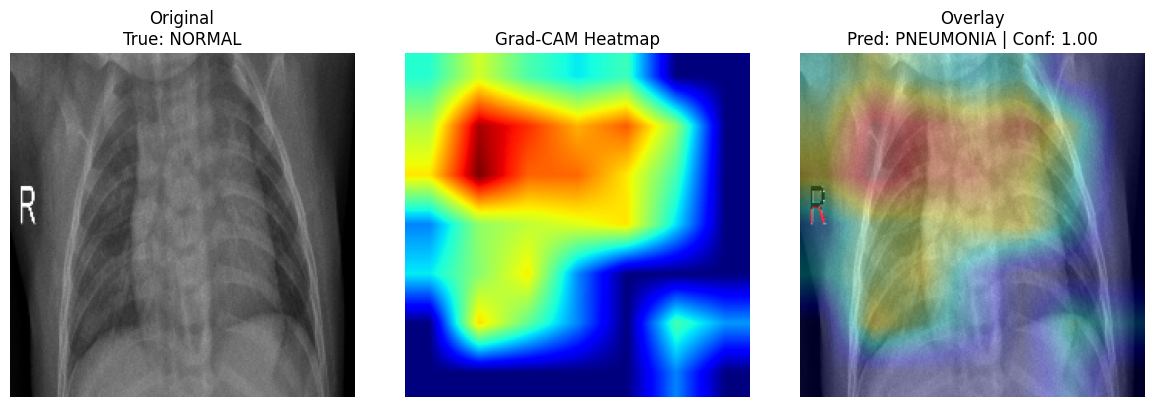


 False Negative: PNEUMONIA predicted as NORMAL
Image: /content/chest_xray/test/PNEUMONIA/person108_bacteria_511.jpeg


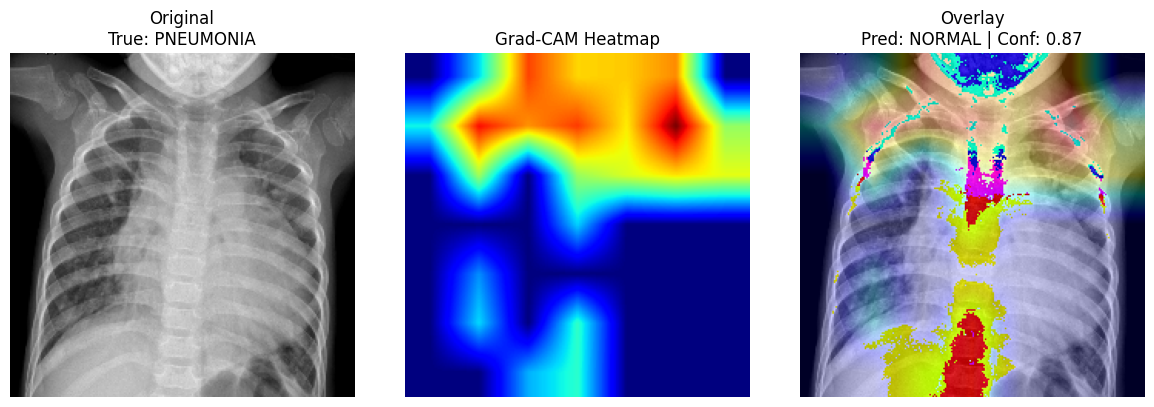

In [ ]:
example_indices = [
    tn_indices[0],
    tp_indices[0],
    fp_indices[0],
    fn_indices[0],
]

titles = [
    "True Negative: NORMAL correctly predicted",
    "True Positive: PNEUMONIA correctly predicted",
    "False Positive: NORMAL predicted as PNEUMONIA",
    "False Negative: PNEUMONIA predicted as NORMAL",
]

for idx, title in zip(example_indices, titles):
    img_path = test_file_paths[idx]
    print("\n", title)
    print("Image:", img_path)
    display_gradcam_clean(img_path, model)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
import pandas as pd
import numpy as np

thresholds = np.arange(0.30, 0.91, 0.05)

results = []

for threshold in thresholds:
    y_pred_thr = (y_prob >= threshold).astype(int)

    acc = accuracy_score(y_true, y_pred_thr)
    precision = precision_score(y_true, y_pred_thr)
    recall = recall_score(y_true, y_pred_thr)
    f1 = f1_score(y_true, y_pred_thr)

    cm_thr = confusion_matrix(y_true, y_pred_thr)
    tn, fp, fn, tp = cm_thr.ravel()

    results.append({
        "threshold": round(threshold, 2),
        "accuracy": round(acc, 4),
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "f1": round(f1, 4),
        "false_positive": fp,
        "false_negative": fn,
        "true_positive": tp,
        "true_negative": tn
    })

threshold_df = pd.DataFrame(results)
threshold_df

,threshold,accuracy,precision,recall,f1,false_positive,false_negative,true_positive,true_negative
0,0.30,0.8686,0.8333,0.9872,0.9038,77,5,385,157
1,0.35,0.8718,0.8384,0.9846,0.9057,74,6,384,160
2,0.40,0.8766,0.8440,0.9846,0.9089,71,6,384,163
3,0.45,0.8814,0.8527,0.9795,0.9117,66,8,382,168
4,0.50,0.8798,0.8539,0.9744,0.9102,65,10,380,169
5,0.55,0.8830,0.8578,0.9744,0.9124,63,10,380,171
6,0.60,0.8894,0.8690,0.9692,0.9164,57,12,378,177
7,0.65,0.8926,0.8747,0.9667,0.9184,54,13,377,180
8,0.70,0.8974,0.8808,0.9667,0.9218,51,13,377,183
9,0.75,0.9038,0.8892,0.9667,0.9263,47,13,377,187


In [ ]:

filtered = threshold_df[threshold_df["precision"] >= 0.90]

filtered.sort_values(by=["recall", "f1"], ascending=False)

,threshold,accuracy,precision,recall,f1,false_positive,false_negative,true_positive,true_negative
10,0.80,0.9087,0.9012,0.9590,0.9292,41,16,374,193
11,0.85,0.9183,0.9185,0.9538,0.9358,33,18,372,201
12,0.90,0.9103,0.9239,0.9333,0.9286,30,26,364,204


Classification Report with Best Threshold:
              precision    recall  f1-score   support

      NORMAL       0.92      0.86      0.89       234
   PNEUMONIA       0.92      0.95      0.94       390

    accuracy                           0.92       624
   macro avg       0.92      0.91      0.91       624
weighted avg       0.92      0.92      0.92       624



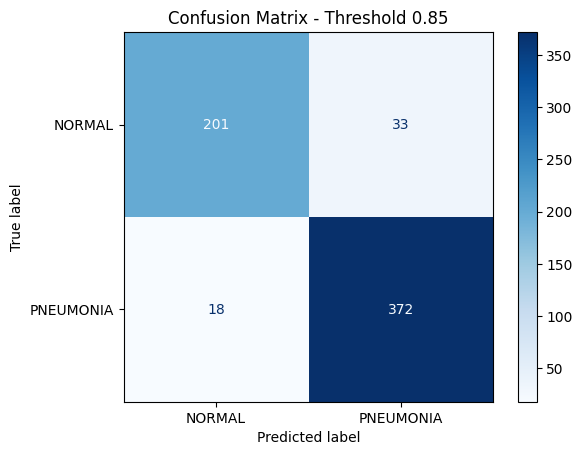

Confusion Matrix:
[[201  33]
 [ 18 372]]


In [ ]:
BEST_THRESHOLD = 0.85

y_pred_best = (y_prob >= BEST_THRESHOLD).astype(int)

print("Classification Report with Best Threshold:")
print(classification_report(
    y_true,
    y_pred_best,
    target_names=class_names
))

cm_best = confusion_matrix(y_true, y_pred_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - Threshold {BEST_THRESHOLD}")
plt.show()

print("Confusion Matrix:")
print(cm_best)

In [ ]:
model.save("/content/pneumonia_mobilenetv2_gradcam.keras")

print("Model saved successfully.")
print("Recommended decision threshold:", BEST_THRESHOLD)

Model saved successfully.
Recommended decision threshold: 0.85
